In [1]:
!pip install -q transformers

from google.colab import drive
drive.mount('/content/drive')

import torch
import tensorflow as tf
import numpy as np
import pandas as pd

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "YOK")
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Mounted at /content/drive
TensorFlow: 2.20.0
PyTorch: 2.11.0+cu128
GPU: NVIDIA A100-SXM4-40GB


In [2]:
DISEASE_LABELS = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration", "Mass",
    "Nodule", "Pneumonia", "Pneumothorax", "Consolidation", "Edema",
    "Emphysema", "Fibrosis", "Pleural_Thickening", "Hernia"
]

# Her hastalık için DenseNet AUC skorları
DENSENET_AUC = {
    "Atelectasis": 0.761, "Cardiomegaly": 0.823, "Effusion": 0.823,
    "Infiltration": 0.661, "Mass": 0.762, "Nodule": 0.654,
    "Pneumonia": 0.662, "Pneumothorax": 0.819, "Consolidation": 0.762,
    "Edema": 0.849, "Emphysema": 0.834, "Fibrosis": 0.736,
    "Pleural_Thickening": 0.733, "Hernia": 0.818
}

# Her hastalık için ViT AUC skorları
VIT_AUC = {
    "Atelectasis": 0.761, "Cardiomegaly": 0.850, "Effusion": 0.829,
    "Infiltration": 0.678, "Mass": 0.746, "Nodule": 0.669,
    "Pneumonia": 0.688, "Pneumothorax": 0.831, "Consolidation": 0.774,
    "Edema": 0.859, "Emphysema": 0.833, "Fibrosis": 0.740,
    "Pleural_Thickening": 0.739, "Hernia": 0.851
}

print("Sabitler yüklendi ✓")

Sabitler yüklendi ✓


In [3]:
import zipfile, io, os
from sklearn.model_selection import train_test_split

ZIP_PATH = "/content/drive/MyDrive/Kaggle_Datasets/nih_chest_xrays/data.zip"
SUBSET_SIZE = 50000

# CSV yükle
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    csv_name = next(n for n in zf.namelist() if 'Data_Entry' in n and n.endswith('.csv'))
    csv_bytes = zf.read(csv_name)
df = pd.read_csv(io.BytesIO(csv_bytes))

# ZIP yolları
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    all_names = zf.namelist()
filename_to_zippath = {n.split('/')[-1]: n for n in all_names if n.lower().endswith('.png')}
df['zip_path'] = df['Image Index'].map(filename_to_zippath)
df = df.dropna(subset=['zip_path']).reset_index(drop=True)

# Etiketler
def encode_labels(s):
    parts = s.split('|')
    return [1.0 if d in parts else 0.0 for d in DISEASE_LABELS]
label_matrix = np.stack(df['Finding Labels'].apply(encode_labels).values)
for i, d in enumerate(DISEASE_LABELS):
    df[d] = label_matrix[:, i]

# TAM AYNI split
unique_patients = df['Patient ID'].unique()
train_p, test_p = train_test_split(unique_patients, test_size=0.2, random_state=42)
train_p, val_p  = train_test_split(train_p,         test_size=0.1, random_state=42)
test_df = df[df['Patient ID'].isin(test_p)].reset_index(drop=True)
n_test  = int(SUBSET_SIZE * 0.20)
test_df = test_df.sample(n=min(n_test, len(test_df)), random_state=42).reset_index(drop=True)
print(f"Test seti: {len(test_df)} görüntü")

Test seti: 10000 görüntü


In [4]:
from tqdm.auto import tqdm

EXTRACT_DIR = "/content/nih_images"
os.makedirs(EXTRACT_DIR, exist_ok=True)

all_needed = set(test_df['zip_path'].tolist())
already    = {f for f in os.listdir(EXTRACT_DIR)}
to_do      = [p for p in all_needed if os.path.basename(p) not in already]
print(f"Extract edilecek: {len(to_do)}")

if to_do:
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        for zip_inner in tqdm(to_do, desc="Extracting"):
            target = os.path.join(EXTRACT_DIR, os.path.basename(zip_inner))
            with open(target, 'wb') as f:
                f.write(zf.read(zip_inner))

test_df['local_path'] = test_df['zip_path'].apply(
    lambda p: os.path.join(EXTRACT_DIR, os.path.basename(p))
)
test_df = test_df[test_df['local_path'].apply(os.path.exists)].reset_index(drop=True)
print(f"Test seti hazır: {len(test_df)} görüntü ✓")

Extract edilecek: 10000


Extracting:   0%|          | 0/10000 [00:00<?, ?it/s]

Test seti hazır: 10000 görüntü ✓


In [35]:
# DenseNet modeli yükle
DENSENET_PATH = "/content/drive/MyDrive/densenet121_pulmoai_50k_best.h5"
densenet_model = tf.keras.models.load_model(DENSENET_PATH)
print("DenseNet yüklendi ✓")

IMG_SIZE   = 224
BATCH_SIZE = 32

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

# test_df sırası sabit — shuffle YOK
paths  = test_df['local_path'].values
labels = test_df[DISEASE_LABELS].values.astype('float32')

test_ds = (
    tf.data.Dataset.from_tensor_slices((paths, labels))
    .map(load_img, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("DenseNet tahminleri alınıyor...")
densenet_preds = densenet_model.predict(test_ds)
y_true = test_df[DISEASE_LABELS].values
print(f"DenseNet preds shape: {densenet_preds.shape} ✓")

DenseNet yüklendi ✓
DenseNet tahminleri alınıyor...
313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 98ms/step
DenseNet preds shape: (10000, 14) ✓


In [18]:
from transformers import ViTModel
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class ViTChestXray(nn.Module):
    def __init__(self, num_labels=14, dropout=0.3):
        super().__init__()
        self.vit = ViTModel.from_pretrained(
            'google/vit-base-patch16-224',
            attn_implementation='eager'
        )
        hidden_size     = self.vit.config.hidden_size
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, pixel_values):
        outputs    = self.vit(pixel_values=pixel_values)
        cls_output = outputs.last_hidden_state[:, 0, :]
        cls_output = self.dropout(cls_output)
        return torch.sigmoid(self.classifier(cls_output))

VIT_PATH = "/content/drive/MyDrive/vit_pulmoai_best.pt"
vit_model = ViTChestXray(num_labels=14).to(DEVICE)
vit_model.load_state_dict(torch.load(VIT_PATH, map_location=DEVICE))
vit_model.eval()
print("ViT yüklendi ✓")

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = Image.open(row['local_path']).convert('RGB')
        label = torch.tensor(row[DISEASE_LABELS].values.astype('float32'))
        if self.transform:
            img = self.transform(img)
        return img, label

test_dataset = ChestXrayDataset(test_df, transform=val_transform)
test_loader  = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,  # KESİNLİKLE FALSE
    num_workers=4,
    pin_memory=True
)

print("ViT tahminleri alınıyor...")
vit_preds_list = []
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs  = imgs.to(DEVICE)
        preds = vit_model(imgs)
        vit_preds_list.append(preds.cpu().numpy())

vit_preds = np.concatenate(vit_preds_list)

# Sıralama kontrolü
print(f"ViT preds shape: {vit_preds.shape} ✓")
print(f"test_df satır sayısı: {len(test_df)}")
print(f"DenseNet: {densenet_preds.shape[0]} | ViT: {vit_preds.shape[0]}")
assert densenet_preds.shape == vit_preds.shape, "HATA: Şekiller eşleşmiyor!"
print("Sıralama kontrolü geçti ✓")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ViT yüklendi ✓
ViT tahminleri alınıyor...
ViT preds shape: (10000, 14) ✓
test_df satır sayısı: 10000
DenseNet: 10000 | ViT: 10000
Sıralama kontrolü geçti ✓


In [36]:
# ## 19 - Sınıf Bazlı Dinamik Ağırlıklı Late Fusion (Per-Class Ensemble)

fusion_preds = np.zeros_like(densenet_preds)

print(f"{'Hastalik':22s}  {'DenseNet W':>10}  {'ViT W':>7}  {'Lider Model'}")
print("-" * 55)

for i, disease in enumerate(DISEASE_LABELS):
    # Test setindeki tekil model başarılarını sözlüklerden çekiyoruz
    d_auc = DENSENET_AUC[disease]
    v_auc = VIT_AUC[disease]

    # Dinamik ağırlık atama mantığı
    if d_auc > v_auc:
        # DenseNet bu hastalıkta daha iyi, ona %60, ViT'e %40 ver
        w_d = 0.60
        w_v = 0.40
        leader = "DenseNet"
    elif v_auc > d_auc:
        # ViT bu hastalıkta daha iyi, ona %60, DenseNet'e %40 ver
        w_d = 0.40
        w_v = 0.60
        leader = "ViT"
    else:
        # Eğer eşitlerse performansı bozmamak için jenerik yarı yarıya al
        w_d = 0.50
        w_v = 0.50
        leader = "Eşit (0.5/0.5)"

    # İlgili hastalığın sütununu kendi özel ağırlıklarıyla hesapla
    fusion_preds[:, i] = (w_d * densenet_preds[:, i]) + (w_v * vit_preds[:, i])

    print(f"{disease:22s}  {w_d:10.2f}  {w_v:7.2f}  {leader}")

print("-" * 55)
print("Sınıf bazlı dinamik füzyon başarıyla tamamlandı ✓")
print(f"Fusion preds shape: {fusion_preds.shape}")

Hastalik                DenseNet W    ViT W  Lider Model
-------------------------------------------------------
Atelectasis                   0.50     0.50  Eşit (0.5/0.5)
Cardiomegaly                  0.40     0.60  ViT
Effusion                      0.40     0.60  ViT
Infiltration                  0.40     0.60  ViT
Mass                          0.60     0.40  DenseNet
Nodule                        0.40     0.60  ViT
Pneumonia                     0.40     0.60  ViT
Pneumothorax                  0.40     0.60  ViT
Consolidation                 0.40     0.60  ViT
Edema                         0.40     0.60  ViT
Emphysema                     0.60     0.40  DenseNet
Fibrosis                      0.40     0.60  ViT
Pleural_Thickening            0.40     0.60  ViT
Hernia                        0.40     0.60  ViT
-------------------------------------------------------
Sınıf bazlı dinamik füzyon başarıyla tamamlandı ✓
Fusion preds shape: (10000, 14)


In [37]:
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

print(f"{'Hastalik':22s}  {'En Iyi T':>8}  {'AUC':>6}  {'Sens':>6}  {'Spec':>6}  {'F1':>6}")
print("-" * 66)

fusion_aucs = []

for i, disease in enumerate(DISEASE_LABELS):
    try:
        auc = roc_auc_score(y_true[:, i], fusion_preds[:, i])
    except:
        auc = float('nan')
    fusion_aucs.append(auc)

    # F1 maximize eden optimal threshold
    best_t, best_f1 = 0.5, -1
    for t in np.linspace(0.01, 0.50, 50):
        score = f1_score(y_true[:, i],
                         (fusion_preds[:, i] >= t).astype(int),
                         zero_division=0)
        if score > best_f1:
            best_f1, best_t = score, t

    yb = (fusion_preds[:, i] >= best_t).astype(int)
    try:
        tn, fp, fn, tp = confusion_matrix(y_true[:, i], yb, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
        spec = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    except:
        sens = spec = float('nan')

    print(f"{disease:22s}  {best_t:8.3f}  {auc:6.3f}  {sens:6.3f}  {spec:6.3f}  {best_f1:6.3f}")

print("-" * 66)
print(f"{'Makro Ortalama':22s}  {'--':>8}  {np.nanmean(fusion_aucs):6.3f}")

Hastalik                En Iyi T     AUC    Sens    Spec      F1
------------------------------------------------------------------
Atelectasis                0.170   0.768   0.437   0.880   0.344
Cardiomegaly               0.100   0.857   0.379   0.969   0.311
Effusion                   0.260   0.838   0.594   0.871   0.462
Infiltration               0.240   0.681   0.423   0.832   0.387
Mass                       0.110   0.750   0.310   0.935   0.239
Nodule                     0.110   0.678   0.188   0.958   0.203
Pneumonia                  0.010   0.692   0.565   0.698   0.049
Pneumothorax               0.130   0.841   0.357   0.963   0.336
Consolidation              0.090   0.783   0.368   0.907   0.208
Edema                      0.060   0.865   0.416   0.942   0.204
Emphysema                  0.090   0.856   0.259   0.983   0.267
Fibrosis                   0.040   0.766   0.211   0.961   0.121
Pleural_Thickening         0.080   0.751   0.204   0.962   0.161
Hernia                 

In [38]:
# Hangi hastalık için kim seçildi görelim
for i, disease in enumerate(DISEASE_LABELS):
    w_d = DENSENET_AUC[disease]
    w_v = VIT_AUC[disease]
    winner = "DenseNet" if w_d > w_v else ("ViT" if w_v > w_d else "Ortalama")
    print(f"{disease:22s} → {winner} (D:{w_d:.3f} V:{w_v:.3f})")

Atelectasis            → Ortalama (D:0.761 V:0.761)
Cardiomegaly           → ViT (D:0.823 V:0.850)
Effusion               → ViT (D:0.823 V:0.829)
Infiltration           → ViT (D:0.661 V:0.678)
Mass                   → DenseNet (D:0.762 V:0.746)
Nodule                 → ViT (D:0.654 V:0.669)
Pneumonia              → ViT (D:0.662 V:0.688)
Pneumothorax           → ViT (D:0.819 V:0.831)
Consolidation          → ViT (D:0.762 V:0.774)
Edema                  → ViT (D:0.849 V:0.859)
Emphysema              → DenseNet (D:0.834 V:0.833)
Fibrosis               → ViT (D:0.736 V:0.740)
Pleural_Thickening     → ViT (D:0.733 V:0.739)
Hernia                 → ViT (D:0.818 V:0.851)


Hastalik                DenseNet     ViT   Fusion    En Iyi
------------------------------------------------------------
Atelectasis                0.761   0.761    0.768    Fusion
Cardiomegaly               0.823   0.850    0.857    Fusion
Effusion                   0.823   0.829    0.838    Fusion
Infiltration               0.661   0.678    0.681    Fusion
Mass                       0.762   0.746    0.750  DenseNet
Nodule                     0.654   0.669    0.678    Fusion
Pneumonia                  0.662   0.688    0.692    Fusion
Pneumothorax               0.819   0.831    0.841    Fusion
Consolidation              0.762   0.774    0.783    Fusion
Edema                      0.849   0.859    0.865    Fusion
Emphysema                  0.834   0.833    0.856    Fusion
Fibrosis                   0.736   0.740    0.766    Fusion
Pleural_Thickening         0.733   0.739    0.751    Fusion
Hernia                     0.818   0.851    0.857    Fusion
---------------------------------------

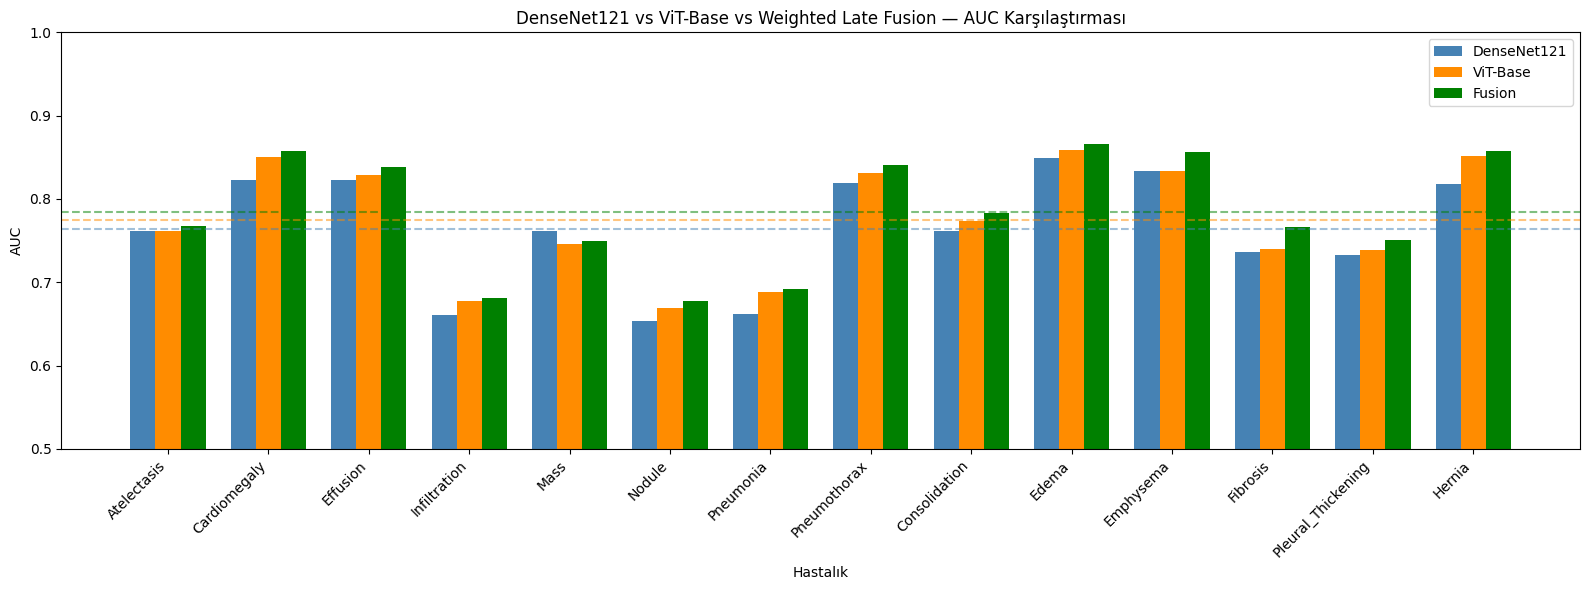

In [39]:
import matplotlib.pyplot as plt

densenet_aucs_list = list(DENSENET_AUC.values())
vit_aucs_list      = list(VIT_AUC.values())

print(f"{'Hastalik':22s}  {'DenseNet':>8}  {'ViT':>6}  {'Fusion':>7}  {'En Iyi':>8}")
print("-" * 60)

for i, disease in enumerate(DISEASE_LABELS):
    d = densenet_aucs_list[i]
    v = vit_aucs_list[i]
    f = fusion_aucs[i]
    best = max(d, v, f)
    winner = "DenseNet" if best == d else ("ViT" if best == v else "Fusion")
    print(f"{disease:22s}  {d:8.3f}  {v:6.3f}  {f:7.3f}  {winner:>8}")

print("-" * 60)
print(f"{'Makro Ortalama':22s}  {np.mean(densenet_aucs_list):8.3f}  "
      f"{np.mean(vit_aucs_list):6.3f}  {np.nanmean(fusion_aucs):7.3f}")

# Görsel karşılaştırma
x = np.arange(len(DISEASE_LABELS))
width = 0.25

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(x - width, densenet_aucs_list, width, label='DenseNet121', color='steelblue')
ax.bar(x,         vit_aucs_list,      width, label='ViT-Base',    color='darkorange')
ax.bar(x + width, fusion_aucs,        width, label='Fusion',      color='green')

ax.axhline(y=np.mean(densenet_aucs_list), color='steelblue',  linestyle='--', alpha=0.5)
ax.axhline(y=np.mean(vit_aucs_list),      color='darkorange', linestyle='--', alpha=0.5)
ax.axhline(y=np.nanmean(fusion_aucs),     color='green',      linestyle='--', alpha=0.5)

ax.set_xlabel('Hastalık')
ax.set_ylabel('AUC')
ax.set_title('DenseNet121 vs ViT-Base vs Weighted Late Fusion — AUC Karşılaştırması')
ax.set_xticks(x)
ax.set_xticklabels(DISEASE_LABELS, rotation=45, ha='right')
ax.legend()
ax.set_ylim(0.5, 1.0)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fusion_comparison.png', dpi=150)
plt.show()